# 03 - How storms relate to outages

Joins NOAA storm events to EAGLE-I outages to see which storms cause the most outages, and when and where they happen.

Questions:
1. Which storm types cause the most outages, and how big are those outages?
2. When and where were the most customers out, and which storm caused it?
3. Which single storms (NOAA episodes) were the worst?
4. Does storm strength (wind speed, tornado rating, damage) predict outage size?
5. How many large outages have no storm record at all?

**Approach.** For each (storm event, county) row we look at the county's outages in a window around the event and record the
peak. All joins run in DuckDB, so nothing big is loaded into pandas.

**Definitions used throughout**
- **Hourly outage** = the median of the 15-min readings in that county-hour. The max picks up one-reading spikes,
  e.g. Irma reaches 10M customers at a single hour and then drops back to 7.5M.
- **Estimated customers** = Census housing units x 1.2 (homes plus businesses; notebook 01 found about 1.1-1.2 customers per
  home outside NC). EAGLE-I's MCC counts are wrong for North Carolina, so we don't use them here. Hourly outages are capped at
  this number.
- **Event window** = 1 h before the event starts to 12 h after it ends. Long events are cut at 48 h after the start before the 12 h is added.
- **Peak share** = window peak / estimated customers. A **major outage** is a peak share of 5% or more.
- **Customer-hours** = sum of hourly customers out over the window, so it combines how many were out and for how long.

In [1]:
import sys
sys.path.insert(0, "..")
import re

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap, LogNorm
import seaborn as sns

from src import config as C
from src.data import path

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)

# Chart styling: one blue for single-series bars, a fixed categorical order, a one-hue blue ramp for heatmaps
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#a3a29c"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ = LinearSegmentedColormap.from_list("blue_seq", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#8a8984", "axes.titleweight": "bold", "axes.titlesize": 12,
})
fmt_k = mtick.FuncFormatter(lambda v, _: f"{v/1e6:g}M" if v >= 1e6 else f"{v/1e3:g}k" if v >= 1e3 else f"{v:g}")

def heat_axes(ax, months=True):
    # Common cleanup for heatmaps: no grid lines through cells, horizontal row labels, month names
    ax.grid(False)
    ax.tick_params(axis="y", rotation=0)
    if months:
        ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"], rotation=0)

MAJOR = 0.05         # peak share that counts as a "major" outage
PRE_H, POST_H, MAX_H = 1, 12, 48   # event window: start - 1h ... min(end, start + 48h) + 12h

con = duckdb.connect()
# DuckDB reads the local Parquet files directly. Without a local copy it streams from Hugging Face (needs `hf auth login`).
if list((C.PROCESSED_DIR / "eaglei").glob("outages_*.parquet")):
    OUT = (C.PROCESSED_DIR / "eaglei" / "outages_*.parquet").as_posix()
else:
    OUT = f"hf://datasets/{C.HF_REPO_ID}/eaglei/outages_*.parquet"
STORMS = path("storms/storm_event_counties.parquet").replace("\\", "/")
CENSUS = path("reference/county_census.parquet").replace("\\", "/")

## 1. Check: are EAGLE-I timestamps UTC?

The data README leaves this open. We line up short, county-reported thunderstorm wind events (2022-2024) and average the
county's outages for each hour before and after `begin_utc`. If EAGLE-I uses UTC, outages should jump at hour 0 in both
Eastern and Central counties. If it uses local time, the jump would show up 5-6 hours earlier.

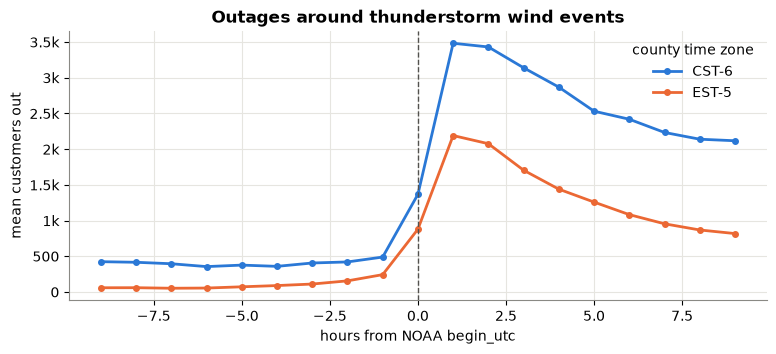

In [2]:
tz = con.sql(f'''
with ev as (
  select fips_code, date_trunc('hour', begin_utc) as h0, cz_timezone
  from '{STORMS}'
  where event_type = 'Thunderstorm Wind' and mapped_from = 'county' and year between 2022 and 2024
),
o as (
  select fips_code, date_trunc('hour', run_start_time) as hr, median(customers_out) as out
  from '{OUT}' where year(run_start_time) between 2022 and 2024 group by all
)
select ev.cz_timezone, datediff('hour', ev.h0, o.hr) as lag_h, avg(o.out) as mean_out
from ev join o on o.fips_code = ev.fips_code
  and o.hr between ev.h0 - interval 9 hour and ev.h0 + interval 9 hour
group by all order by all
''').df()

fig, ax = plt.subplots(figsize=(9, 3.5))
for (zone, g), color in zip(tz.groupby("cz_timezone"), [BLUE, ORANGE]):
    ax.plot(g["lag_h"], g["mean_out"], marker="o", ms=4, lw=2, color=color, label=zone)
ax.axvline(0, color="#52514e", lw=1, ls="--")
ax.set(xlabel="hours from NOAA begin_utc", ylabel="mean customers out", title="Outages around thunderstorm wind events")
ax.yaxis.set_major_formatter(fmt_k)
ax.legend(title="county time zone", frameon=False)
plt.show()

**EAGLE-I `run_start_time` is UTC.** Outages jump at hour 0 for both EST and CST counties, so the two time zones need no
different shift. From here on we join on `begin_utc` / `end_utc`.

## 2. Build the joined tables

1. `hourly`: one row per county-hour (median of the 15-min readings, capped at estimated customers).
2. `ev`: storm-event x county rows that can cause outages, limited to the period EAGLE-I covers (from 2014-11-01).
   We drop types that don't affect the grid (Drought, Heat, Rip Current, Fog, High Surf, Funnel Cloud, Frost/Freeze,
   Astronomical Low Tide, Dust Devil). Their windows also run for weeks and would pick up unrelated outages.
3. `imp`: per event-county, the outage peak, when it happened, customer-hours, and the average level in the 24 h before.

To keep the join fast, each window is expanded into hourly keys and joined on (county, hour) equality, not a range join.

In [3]:
con.sql(f'''
create or replace table cust as
select fips_code, acs_year, housing_units, population, 1.2 * housing_units as cust_est,
       split_part(county_name, ', ', 1) as county, split_part(county_name, ', ', 2) as state_name
from '{CENSUS}'
''')

con.sql(f'''
create or replace table hourly as
select o.fips_code, o.hr, least(o.out, c.cust_est) as out
from (select fips_code, date_trunc('hour', run_start_time) as hr, median(customers_out) as out
      from '{OUT}' where customers_out is not null group by all) o
join cust c on c.fips_code = o.fips_code and c.acs_year = least(year(o.hr), 2024)
''')

SKIP = ["Drought", "Heat", "Excessive Heat", "Rip Current", "Dense Fog", "Freezing Fog", "Astronomical Low Tide",
        "High Surf", "Dust Devil", "Funnel Cloud", "Frost/Freeze"]
first_hr, last_hr = con.sql("select min(hr), max(hr) from hourly").fetchone()

con.sql(f'''
create or replace table ev as
select event_id, episode_id, s.fips_code, event_type, year, state_abbr, begin_utc, end_utc, begin_local,
       magnitude, magnitude_type, tor_f_scale, damage_property_usd, mapped_from, c.cust_est,
       date_trunc('hour', begin_utc) - interval {PRE_H} hour as w0,
       date_trunc('hour', least(end_utc, begin_utc + interval {MAX_H} hour)) + interval {POST_H} hour as w1
from '{STORMS}' s
join cust c on c.fips_code = s.fips_code and c.acs_year = least(s.year, 2024)  -- also drops the 59 bad GA FIPS rows
where event_type not in ({", ".join(f"'{t}'" for t in SKIP)})
  and begin_utc >= '{first_hr}' and begin_utc <= '{last_hr}'
''')

con.sql('''
create or replace table imp as
with win as (select event_id, fips_code, unnest(generate_series(w0, w1, interval 1 hour)) as hr from ev),
pre as (select event_id, fips_code, unnest(generate_series(w0 - interval 24 hour, w0 - interval 1 hour, interval 1 hour)) as hr from ev),
a as (select w.event_id, w.fips_code, coalesce(max(h.out), 0) as peak, coalesce(sum(h.out), 0) as cust_hours,
             arg_max(w.hr, h.out) as peak_hr
      from win w left join hourly h using (fips_code, hr) group by all),
b as (select p.event_id, p.fips_code, coalesce(sum(h.out), 0) / 24.0 as pre_level
      from pre p left join hourly h using (fips_code, hr) group by all)
select ev.*, a.peak, a.cust_hours, a.peak_hr, b.pre_level,
       a.peak / ev.cust_est as peak_share,
       a.peak / ev.cust_est >= {MAJOR} as major,
       date_diff('hour', date_trunc('hour', ev.begin_utc), a.peak_hr) as hours_to_peak
from ev join a using (event_id, fips_code) join b using (event_id, fips_code)
'''.replace("{MAJOR}", str(MAJOR)))

imp = con.sql("select * from imp").df()
dropped = con.sql(f"select count(*) from '{STORMS}'").fetchone()[0] - len(imp)
print(f"hourly rows: {con.sql('select count(*) from hourly').fetchone()[0]:,} | event-county rows kept: {len(imp):,} "
      f"(dropped {dropped:,}: non-grid types, before Nov 2014, bad FIPS)")
print(f"outage data covers {first_hr} to {last_hr}")
imp[["peak", "peak_share", "cust_hours", "pre_level", "hours_to_peak"]].describe().round(2)

hourly rows: 14,969,039 | event-county rows kept: 78,509 (dropped 14,343: non-grid types, before Nov 2014, bad FIPS)
outage data covers 2014-11-01 04:00:00 to 2025-12-31 23:00:00


,peak,peak_share,cust_hours,pre_level,hours_to_peak
count,78509.00,78509.00,78509.00,78509.00,67319.0
mean,2943.82,0.04,29633.12,135.74,4.03
std,18034.48,0.11,332334.27,1916.87,5.87
min,0.00,0.00,0.00,0.00,-1.0
25%,22.00,0.00,69.00,0.17,1.0
50%,363.00,0.01,1233.00,3.29,2.0
75%,1748.00,0.03,7170.00,29.06,5.0
max,1210689.62,1.00,25137388.12,233808.04,60.0


## 3. Which storm types cause the most outages?

Two different questions:
- **Per event:** when this type of storm hits a county, how bad is the outage? (median peak share, % major)
- **In total:** which types caused the most customer-hours out across the whole period? (count x severity)

In [4]:
by_type = imp.groupby("event_type").agg(
    rows=("event_id", "size"),
    median_peak=("peak", "median"),
    median_share=("peak_share", "median"),
    pct_major=("major", "mean"),
    p90_peak=("peak", lambda s: s.quantile(0.9)),
    total_cust_hours=("cust_hours", "sum"),
    median_hours_to_peak=("hours_to_peak", "median"),
).sort_values("median_share", ascending=False)
by_type["pct_major"] *= 100
by_type["median_share"] *= 100
by_type.round(1)

,rows,median_peak,median_share,pct_major,p90_peak,total_cust_hours,median_hours_to_peak
event_type,,,,,,,
Hurricane (Typhoon),202,15445.200195,75.0,98.5,247946.3,312376712.4,15.0
Blizzard,6,759.000000,14.9,50.0,10563.0,68734.5,8.0
Tropical Storm,2007,2920.000000,8.5,57.9,27973.0,534681432.9,8.0
Storm Surge/Tide,182,6433.000000,5.8,53.8,110527.5,128617038.0,8.0
High Wind,804,591.000000,1.8,30.7,9211.0,26051758.2,3.0
Tornado,3237,628.000000,1.5,30.2,9193.9,116749060.8,2.0
Ice Storm,210,466.200012,1.4,35.7,6692.5,7974305.0,13.0
Strong Wind,1173,769.000000,1.4,25.0,8133.5,25813446.5,3.0
Thunderstorm Wind,42354,491.500000,1.1,21.3,5441.3,542437612.1,2.0


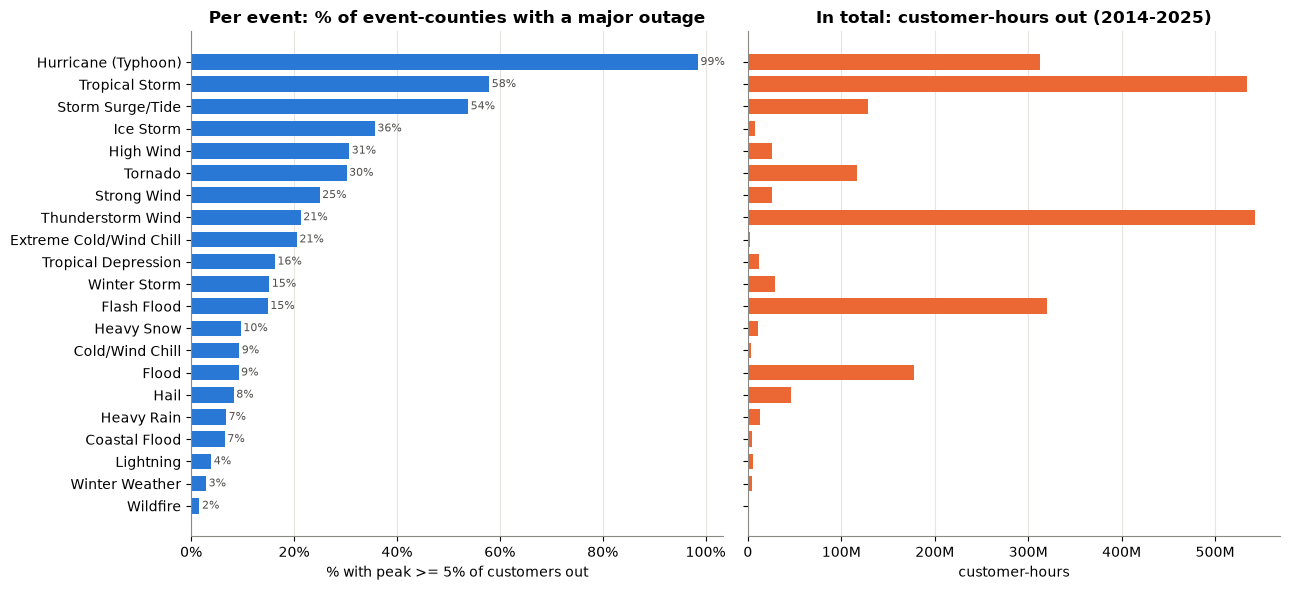

In [5]:
# Keep types with enough rows to say something
t = by_type[by_type["rows"] >= 100]

fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
order = t.sort_values("pct_major").index
axes[0].barh(order, t.loc[order, "pct_major"], color=BLUE, height=0.7)
axes[0].set(title="Per event: % of event-counties with a major outage", xlabel=f"% with peak >= {MAJOR:.0%} of customers out")
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
for y, v in enumerate(t.loc[order, "pct_major"]):
    axes[0].text(v + 0.5, y, f"{v:.0f}%", va="center", fontsize=8, color="#52514e")

axes[1].barh(order, t.loc[order, "total_cust_hours"], color=ORANGE, height=0.7)
axes[1].set(title="In total: customer-hours out (2014-2025)", xlabel="customer-hours")
axes[1].xaxis.set_major_formatter(fmt_k)
axes[1].grid(axis="y", visible=False); axes[0].grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Overlapping events count the same outage more than once (a hurricane day also has Tropical Storm, Storm Surge and High Wind rows
in the same county), so the totals on the right are upper bounds. Use them to rank types, not as real totals.
Thunderstorm Wind has a low per-event rate but so many events that its total is close to the tropical types.

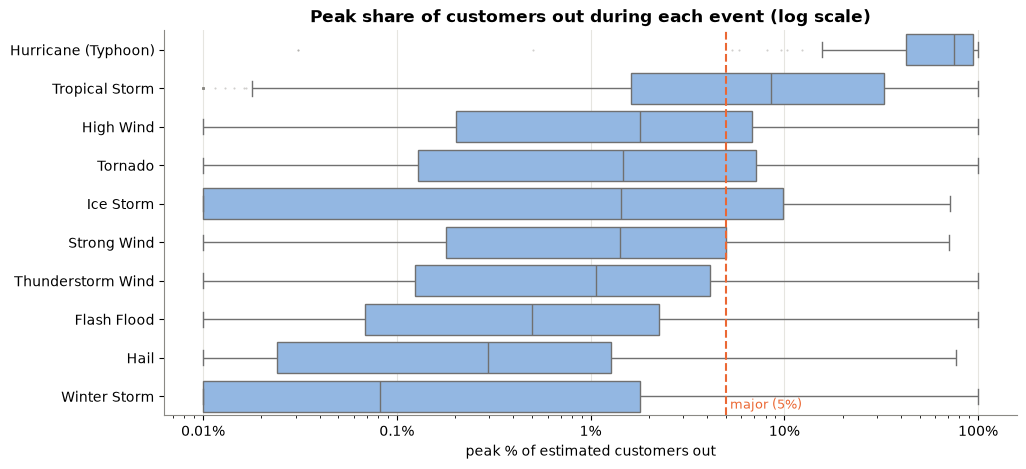

In [6]:
# Peak share distribution for the most common outage-causing types
top = ["Hurricane (Typhoon)", "Tropical Storm", "Tornado", "Thunderstorm Wind", "High Wind", "Strong Wind",
       "Flash Flood", "Hail", "Winter Storm", "Ice Storm"]
d = imp[imp["event_type"].isin(top)].copy()
d["peak_pct"] = (100 * d["peak_share"]).clip(lower=0.01)
order = d.groupby("event_type")["peak_pct"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=d, y="event_type", x="peak_pct", order=order, color="#86b6ef", fliersize=1.5,
            flierprops={"markerfacecolor": "#8a8984", "markeredgecolor": "none", "alpha": 0.4}, ax=ax, log_scale=True)
ax.axvline(100 * MAJOR, color=ORANGE, lw=1.5, ls="--")
ax.text(100 * MAJOR, len(order) - 0.6, f" major ({MAJOR:.0%})", color=ORANGE, fontsize=9, va="bottom")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}%"))
ax.set(title="Peak share of customers out during each event (log scale)", xlabel="peak % of estimated customers out", ylabel="")
plt.show()

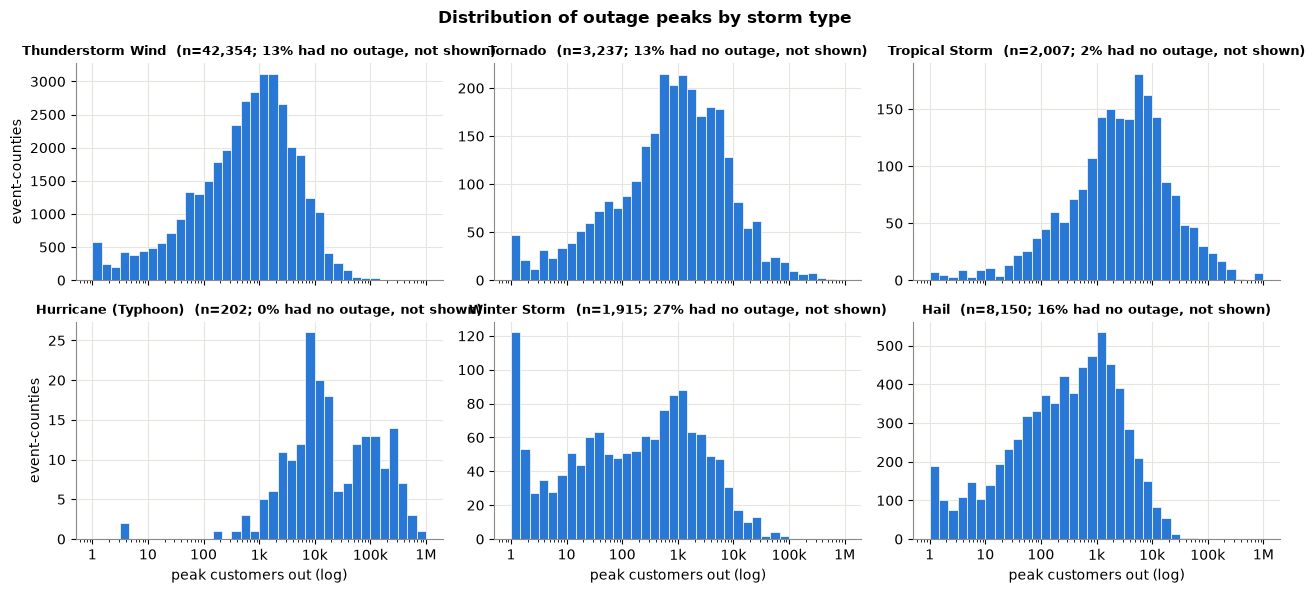

In [7]:
# Histogram of peak customers out: how heavy is the tail for each type?
show = ["Thunderstorm Wind", "Tornado", "Tropical Storm", "Hurricane (Typhoon)", "Winter Storm", "Hail"]
bins = np.logspace(0, 6, 37)
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True)
for ax, ty in zip(axes.flat, show):
    v = imp.loc[imp["event_type"] == ty, "peak"]
    ax.hist(v[v >= 1], bins=bins, color=BLUE, edgecolor="white", linewidth=0.5)
    ax.set_xscale("log")
    ax.set_title(f"{ty}  (n={len(v):,}; {100*(v < 1).mean():.0f}% had no outage, not shown)", fontsize=9)
    ax.xaxis.set_major_formatter(fmt_k)
for ax in axes[1]:
    ax.set_xlabel("peak customers out (log)")
for ax in axes[:, 0]:
    ax.set_ylabel("event-counties")
fig.suptitle("Distribution of outage peaks by storm type", fontweight="bold")
plt.tight_layout()
plt.show()

### Seasonality: storm type x month

Median peak share by month for each type (cells with fewer than 10 event-counties are blank). This shows whether a type is
worse in some seasons, e.g. winter thunderstorms vs summer ones.

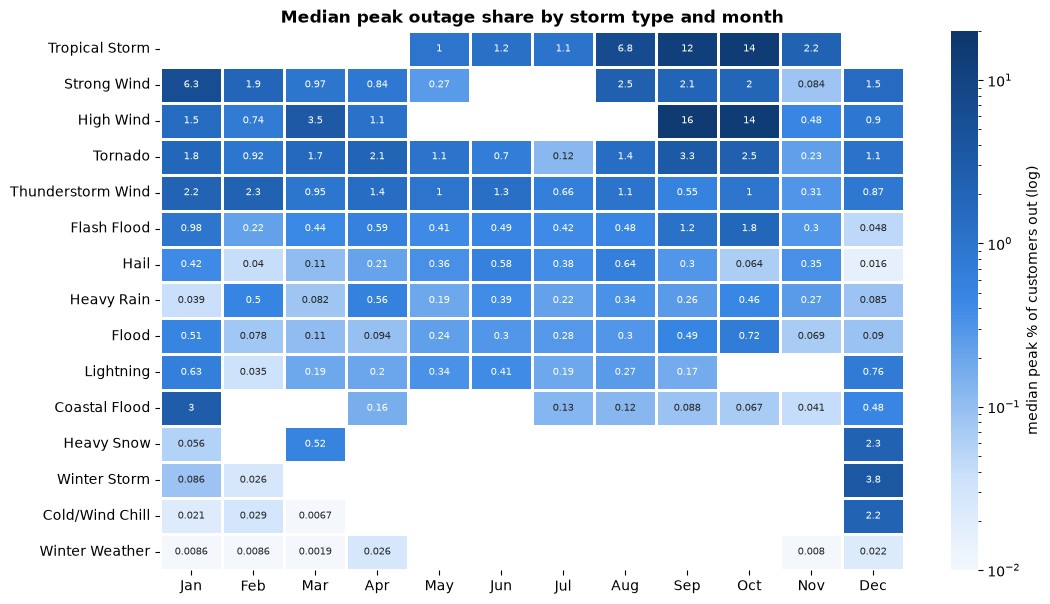

In [8]:
imp["month"] = imp["begin_utc"].dt.month
types = by_type[by_type["rows"] >= 300].index
g = imp[imp["event_type"].isin(types)].groupby(["event_type", "month"])
grid = (100 * g["peak_share"].median()).where(g.size() >= 10).unstack()
grid = grid.loc[grid.median(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(grid, cmap=SEQ, norm=LogNorm(vmin=0.01, vmax=20), annot=True, fmt=".2g", annot_kws={"fontsize": 7},
            linewidths=1, linecolor="white", cbar_kws={"label": "median peak % of customers out (log)"}, ax=ax)
heat_axes(ax)
ax.set(title="Median peak outage share by storm type and month", xlabel="", ylabel="")
plt.show()

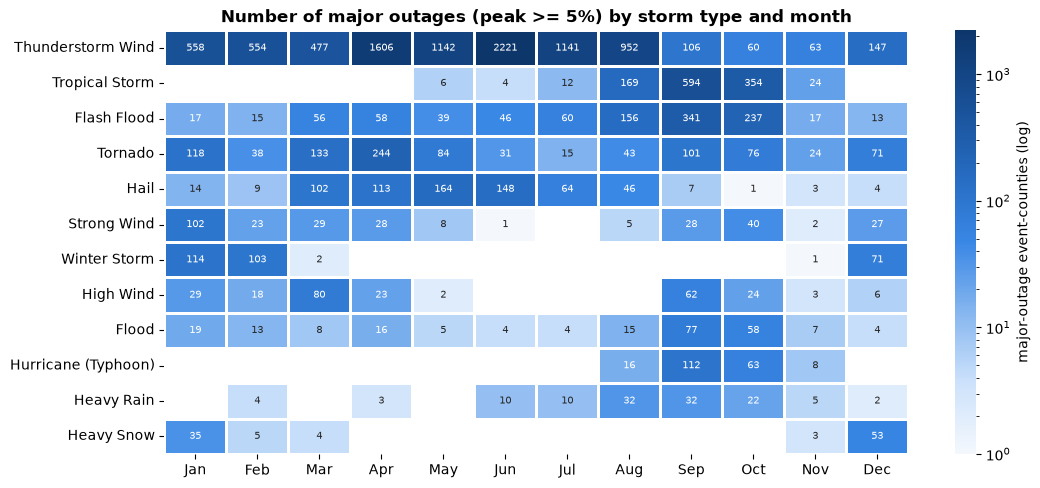

In [9]:
# Count of major outages by type and month: when do the big ones actually happen?
cnt = imp[imp["major"]].pivot_table(index="event_type", columns="month", values="event_id", aggfunc="size", fill_value=0)
cnt = cnt.loc[cnt.sum(axis=1).sort_values(ascending=False).index[:12]]

fig, ax = plt.subplots(figsize=(12, 5.5))
sns.heatmap(cnt.replace(0, np.nan), cmap=SEQ, norm=LogNorm(), annot=cnt, fmt="d", annot_kws={"fontsize": 7},
            linewidths=1, linecolor="white", cbar_kws={"label": "major-outage event-counties (log)"}, ax=ax)
heat_axes(ax)
ax.set(title=f"Number of major outages (peak >= {MAJOR:.0%}) by storm type and month", xlabel="", ylabel="")
plt.show()

### Timing: how long after the storm starts does the outage peak?

This affects the model: it tells us how far past the storm end the target window has to reach.

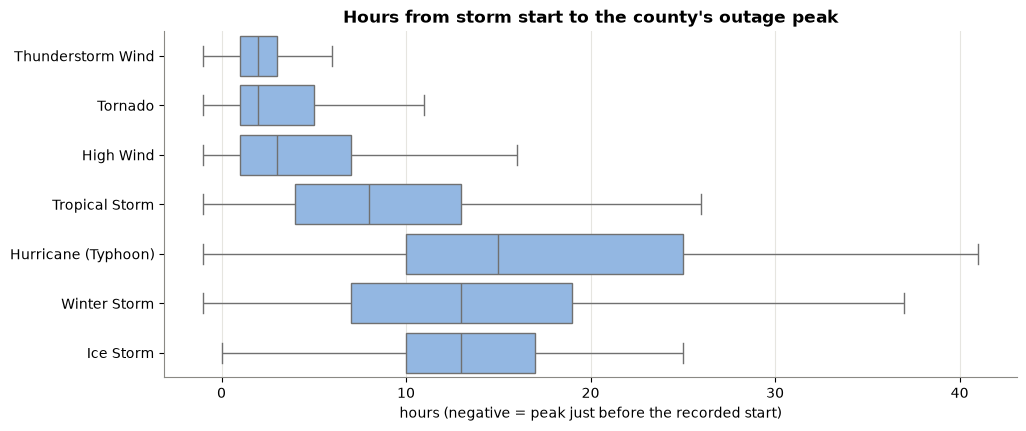

,count,mean,std,min,25%,50%,75%,90%,max
event_type,,,,,,,,,
Thunderstorm Wind,36727.0,2.3,2.6,-1.0,1.0,2.0,3.0,6.0,54.0
Tornado,2805.0,3.4,3.5,-1.0,1.0,2.0,5.0,10.0,13.0
High Wind,718.0,4.7,4.8,-1.0,1.0,3.0,7.0,11.0,24.0
Tropical Storm,1971.0,10.2,8.8,-1.0,4.0,8.0,13.0,21.0,55.0
Hurricane (Typhoon),202.0,16.6,9.6,-1.0,10.0,15.0,25.0,28.0,60.0
Winter Storm,1391.0,13.9,9.2,-1.0,7.0,13.0,19.0,25.0,56.0
Ice Storm,157.0,13.1,5.9,-1.0,10.0,13.0,17.0,21.0,29.0


In [10]:
lag_types = ["Thunderstorm Wind", "Tornado", "High Wind", "Tropical Storm", "Hurricane (Typhoon)", "Winter Storm", "Ice Storm"]
d = imp[imp["event_type"].isin(lag_types) & (imp["peak"] > 0)]

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.boxplot(data=d, x="hours_to_peak", y="event_type", order=lag_types, color="#86b6ef", showfliers=False, ax=ax)
ax.set(title="Hours from storm start to the county's outage peak", xlabel="hours (negative = peak just before the recorded start)", ylabel="")
plt.show()
d.groupby("event_type")["hours_to_peak"].describe(percentiles=[.25, .5, .75, .9]).loc[lag_types].round(1)

## 4. When were the most customers out, and which storm caused it?

Total customers out across all six states, hour by hour. We take the biggest peaks (at least 3 days apart) and credit each one
to a storm: of the storms that hit a county in the 5 days before the peak hour, pick the one whose counties hold the most customers
out at that hour. One hurricane is split into one NOAA episode per state, so storms are matched by name. `share_of_total_in_storm_counties`
is how much of the region-wide total is in that storm's counties. Each storm appears once, at its highest peak.

In [11]:
total = con.sql("select hr, sum(out) as total from hourly group by 1 order by 1").df().set_index("hr")["total"]
daily = total.resample("D").max().fillna(0)

# Top peaks at least 3 days apart
peaks = []
for day, v in daily.sort_values(ascending=False).items():
    if all(abs((day - p).days) >= 3 for p in peaks):
        peaks.append(day)
    if len(peaks) == 40:
        break
peak_hours = [total[d.strftime("%Y-%m-%d")].idxmax() for d in peaks]

# Episode names: pull the storm name from NOAA's episode narrative
eps = con.sql(f'''
select episode_id, any_value(episode_narrative) as narrative,
       string_agg(distinct event_type, ', ') as event_types, min(begin_utc) as begin_utc,
       string_agg(distinct state_abbr, ', ') as states
from '{STORMS}' group by 1
''').df()
TROPICAL = ["Hurricane", "Tropical Storm", "Tropical Depression", "Storm Surge"]
raw = eps["narrative"].str.extract(r"\b(?:Hurricane|Tropical Storm|Tropical Depression|Tropical Cyclone|"
                                   r"Post-Tropical Cyclone|Subtropical Storm|Potential Tropical Cyclone)\s+([A-Z][a-z]+)")[0]
junk = {"Center", "Wind", "Season", "Warning", "Watch", "One", "Six", "Nine", "Nineteen", "Force"}
names = sorted(set(raw.dropna()) - junk)
name_re = re.compile(r"\b(" + "|".join(names) + r")\b")

def label(row):
    # Tropical episodes: any known storm name in the narrative. Other episodes (e.g. Matthew's tornadoes in NC):
    # only when the narrative says "Hurricane <Name>" / "Tropical Storm <Name>" explicitly.
    tropical = any(k in row["event_types"] for k in TROPICAL)
    m = name_re.search(row["narrative"] or "") if tropical else None
    name = m.group(1) if m else (raw[row.name] if raw[row.name] in names else None)
    when = row["begin_utc"].strftime("%b %Y")
    if name:
        return f"{name} ({when})"
    main = row["event_types"].split(", ")[0]
    return f"{main}, {row['states']} ({row['begin_utc'].strftime('%d %b %Y')})"

eps["storm"] = eps.apply(label, axis=1)
con.register("eps_df", eps[["episode_id", "storm"]])
con.sql("create or replace table ev_lab as select ev.*, eps_df.storm from ev join eps_df using (episode_id)")

# Credit each peak hour H to the storm whose counties hold the most customers out at H. A county counts for a storm if
# one of its events started within the 5 days before H (restoration after a hurricane takes days).
def attribute(h):
    att = con.sql(f'''
    select e.storm, sum(h.out) as out_in_storm_counties, count(*) as counties
    from (select distinct storm, fips_code from ev_lab
          where begin_utc between timestamp '{h}' - interval 5 day and timestamp '{h}' + interval 1 hour) e
    join hourly h on h.fips_code = e.fips_code and h.hr = timestamp '{h}'
    group by 1 order by 2 desc limit 1
    ''').df()
    if att.empty:
        return {"storm": "no storm on record", "share_of_total_in_storm_counties": 0.0}
    return {"storm": att.at[0, "storm"], "share_of_total_in_storm_counties": att.at[0, "out_in_storm_counties"] / total[h]}

top_peaks = pd.DataFrame([{"peak_hour_utc": h, "total_out": total[h], **attribute(h)} for h in peak_hours])
# A big hurricane fills several of the top days (landfall, then restoration). Keep each storm's highest peak.
named = top_peaks["storm"] != "no storm on record"
top_peaks = pd.concat([top_peaks[named].drop_duplicates("storm"), top_peaks[~named]]) \
    .sort_values("total_out", ascending=False).head(12).reset_index(drop=True)
top_peaks.style.format({"total_out": "{:,.0f}", "share_of_total_in_storm_counties": "{:.0%}"})

AttributeError: The '.style' accessor requires jinja2

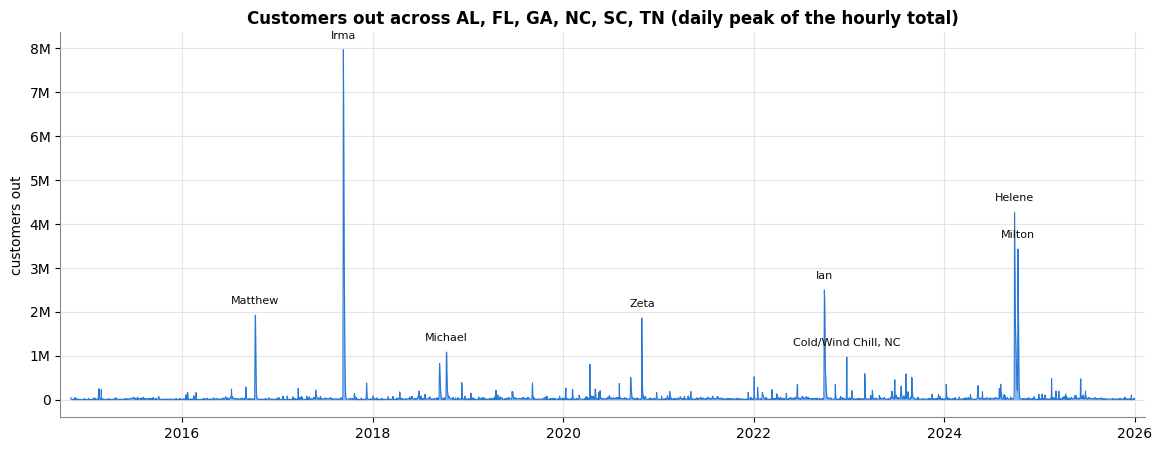

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.fill_between(daily.index, daily.values, color="#86b6ef", lw=0)
ax.plot(daily.index, daily.values, color=BLUE, lw=0.8)
for _, r in top_peaks.head(8).iterrows():
    ax.annotate(r["storm"].split(" (")[0], (r["peak_hour_utc"], r["total_out"]), xytext=(0, 8),
                textcoords="offset points", ha="center", fontsize=8, color="#0b0b0b")
ax.yaxis.set_major_formatter(fmt_k)
ax.set(title="Customers out across AL, FL, GA, NC, SC, TN (daily peak of the hourly total)", ylabel="customers out", xlabel="")
ax.margins(x=0.01)
plt.show()

### Year x month heatmap: total customer-hours out

All outages, storm-linked or not. Shows the worst months and whether the data gets denser over time (EAGLE-I coverage grows,
so later years are inflated somewhat).

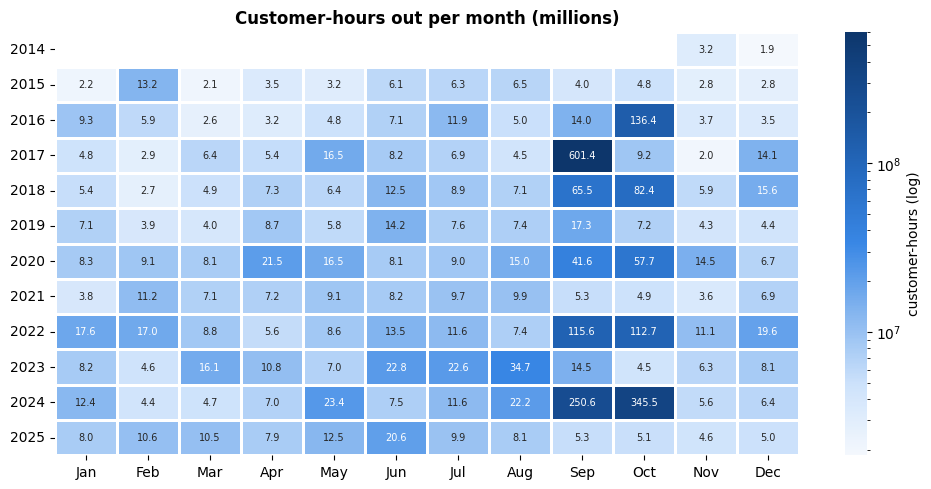

In [ ]:
ym = con.sql("select year(hr) as year, month(hr) as month, sum(out) as cust_hours from hourly group by all").df()
grid = ym.pivot(index="year", columns="month", values="cust_hours")

fig, ax = plt.subplots(figsize=(12, 5.5))
sns.heatmap(grid, cmap=SEQ, norm=LogNorm(), linewidths=1, linecolor="white",
            annot=grid / 1e6, fmt=".1f", annot_kws={"fontsize": 7}, cbar_kws={"label": "customer-hours (log)"}, ax=ax)
heat_axes(ax)
ax.set(title="Customer-hours out per month (millions)", xlabel="", ylabel="")
plt.show()

### Time of day

Local hour when outage-causing storms start vs how often they produce a major outage. Uses `begin_local` (local standard time).

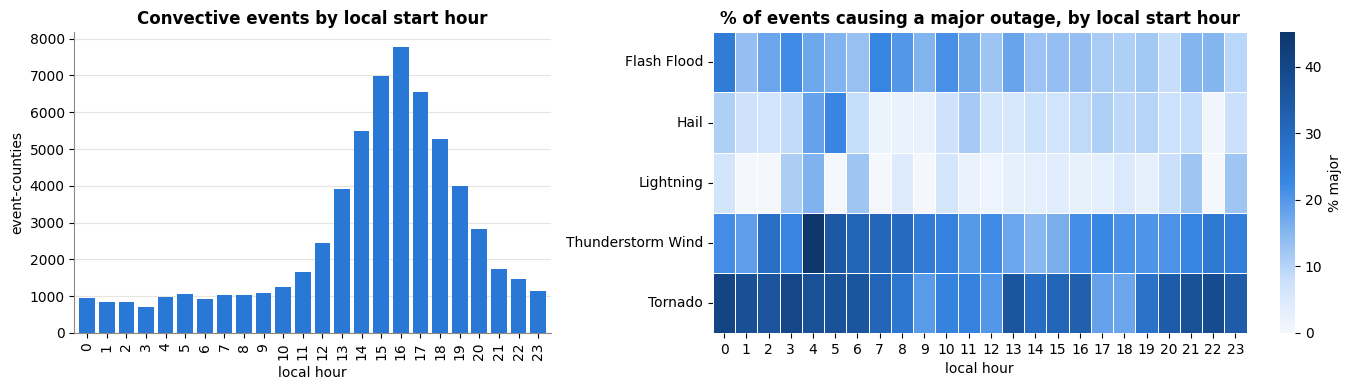

In [ ]:
d = imp[imp["event_type"].isin(["Thunderstorm Wind", "Tornado", "Hail", "Flash Flood", "Lightning"])].copy()
d["hour"] = d["begin_local"].dt.hour
hh = d.groupby(["event_type", "hour"])["major"].mean().unstack() * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 1.4]})
d.groupby("hour").size().plot.bar(ax=axes[0], color=BLUE, width=0.8)
axes[0].set(title="Convective events by local start hour", xlabel="local hour", ylabel="event-counties")
axes[0].grid(axis="x", visible=False)
sns.heatmap(hh, cmap=SEQ, linewidths=0.5, linecolor="white", cbar_kws={"label": "% major"}, ax=axes[1])
axes[1].set(title="% of events causing a major outage, by local start hour", xlabel="local hour", ylabel="")
heat_axes(axes[1], months=False)
plt.tight_layout()
plt.show()

## 5. Where: states and counties

### State x storm type

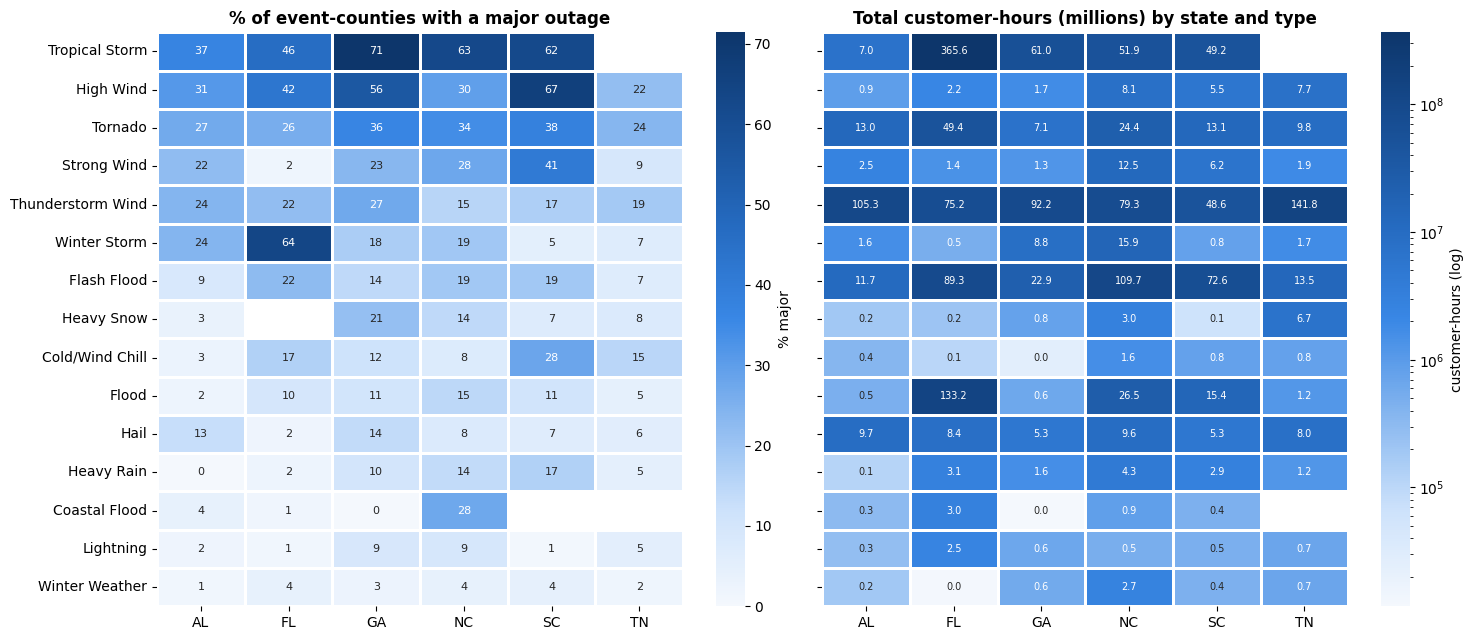

In [ ]:
types = by_type[by_type["rows"] >= 300].index
st = imp[imp["event_type"].isin(types)]
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), sharey=True)

g = st.pivot_table(index="event_type", columns="state_abbr", values="major", aggfunc="mean") * 100
n = st.pivot_table(index="event_type", columns="state_abbr", values="major", aggfunc="size")
g = g.where(n >= 20).loc[by_type.loc[types].sort_values("pct_major", ascending=False).index]
sns.heatmap(g, cmap=SEQ, annot=True, fmt=".0f", annot_kws={"fontsize": 8}, linewidths=1, linecolor="white",
            cbar_kws={"label": "% major"}, ax=axes[0])
axes[0].set(title="% of event-counties with a major outage", xlabel="", ylabel="")
heat_axes(axes[0], months=False)

ch = st.pivot_table(index="event_type", columns="state_abbr", values="cust_hours", aggfunc="sum").loc[g.index]
sns.heatmap(ch, cmap=SEQ, norm=LogNorm(), annot=ch / 1e6, fmt=".1f", annot_kws={"fontsize": 7}, linewidths=1,
            linecolor="white", cbar_kws={"label": "customer-hours (log)"}, ax=axes[1])
axes[1].set(title="Total customer-hours (millions) by state and type", xlabel="", ylabel="")
heat_axes(axes[1], months=False)
plt.tight_layout()
plt.show()

### Counties hit hardest

Two lists, because they answer different questions: counties with the **most customer-hours out during storms** (large, often
coastal counties), and counties that **most often have a major outage** when a storm hits (small, rural, vulnerable grids).
For storm customer-hours we take each county-hour once, so overlapping events aren't double counted.

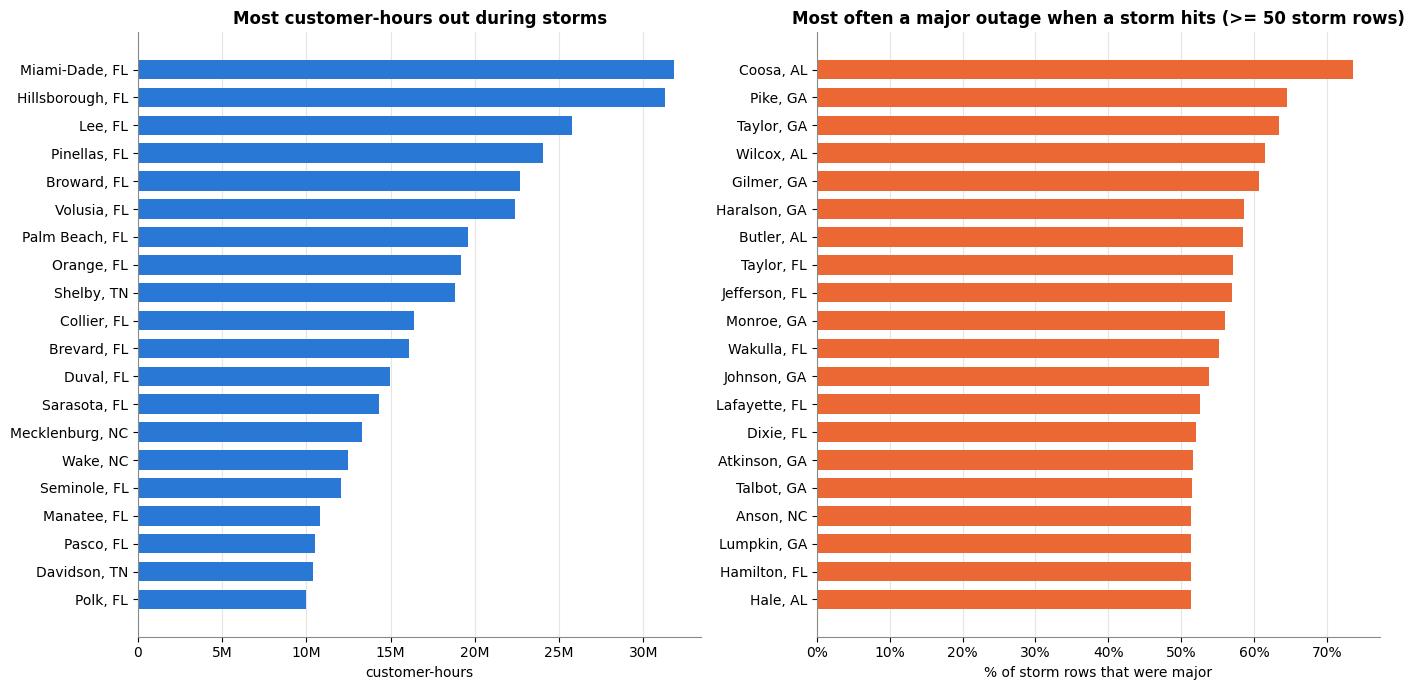

In [ ]:
county = con.sql('''
with storm_hours as (
  select distinct fips_code, unnest(generate_series(w0, w1, interval 1 hour)) as hr from ev
)
select c.fips_code, c.county, c.state_name, any_value(c.cust_est) as cust_est, sum(h.out) as storm_cust_hours
from storm_hours s join hourly h using (fips_code, hr)
join (select * from cust where acs_year = 2023) c using (fips_code)
group by all
''').df()
rate = imp.groupby("fips_code").agg(storm_rows=("event_id", "size"), pct_major=("major", "mean"))
county = county.merge(rate, on="fips_code")
county["label"] = county["county"].str.replace(" County", "") + ", " + county["fips_code"].str[:2].map(C.STATES)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
a = county.nlargest(20, "storm_cust_hours").iloc[::-1]
axes[0].barh(a["label"], a["storm_cust_hours"], color=BLUE, height=0.7)
axes[0].set(title="Most customer-hours out during storms", xlabel="customer-hours")
axes[0].xaxis.set_major_formatter(fmt_k)

b = county[county["storm_rows"] >= 50].nlargest(20, "pct_major").iloc[::-1]
axes[1].barh(b["label"], 100 * b["pct_major"], color=ORANGE, height=0.7)
axes[1].set(title="Most often a major outage when a storm hits (>= 50 storm rows)", xlabel="% of storm rows that were major")
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
for ax in axes:
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

In [ ]:
# Biggest single-county outages, with the storm behind them. One row per county-episode.
worst = (imp.merge(eps[["episode_id", "storm"]], on="episode_id")
            .sort_values("peak", ascending=False)
            .drop_duplicates(["fips_code", "episode_id"]))
worst = worst.merge(county[["fips_code", "label"]], on="fips_code")
worst[["label", "peak_hr", "event_type", "storm", "peak", "peak_share", "cust_hours"]].head(20) \
    .style.format({"peak": "{:,.0f}", "peak_share": "{:.0%}", "cust_hours": "{:,.0f}"})

,label,peak_hr,event_type,storm,peak,peak_share,cust_hours
0,"Miami-Dade, FL",2017-09-11 14:00:00,Tropical Storm,Irma (Sep 2017),"1,210,690",100%,"25,137,388"
1,"Broward, FL",2017-09-11 14:00:00,Tropical Storm,Irma (Sep 2017),"982,058",100%,"19,207,002"
2,"Palm Beach, FL",2017-09-11 14:00:00,Tropical Storm,Irma (Sep 2017),"814,408",100%,"14,945,325"
3,"Hillsborough, FL",2024-10-10 16:00:00,Hurricane (Typhoon),Milton (Oct 2024),"518,089",68%,"10,675,769"
4,"Lee, FL",2022-09-28 23:00:00,Hurricane (Typhoon),Ian (Sep 2022),"454,451",90%,"5,893,180"
5,"Lee, FL",2017-09-11 14:00:00,Hurricane (Typhoon),Irma (Sep 2017),"451,790",98%,"6,022,200"
6,"Pinellas, FL",2024-10-10 23:00:00,Hurricane (Typhoon),Milton (Oct 2024),"431,742",69%,"10,078,794"
7,"Pinellas, FL",2017-09-12 02:00:00,Hurricane (Typhoon),Irma (Sep 2017),"416,254",68%,"8,220,398"
8,"Orange, FL",2017-09-11 16:00:00,Flood,Irma (Sep 2017),"330,886",53%,"5,153,869"
9,"Brevard, FL",2017-09-11 14:00:00,Flood,Irma (Sep 2017),"329,522",100%,"4,423,676"


## 6. The worst storms (NOAA episodes)

An episode groups the related events of one weather system (e.g. all of Hurricane Helene's events in Georgia). One storm that
crosses state lines gets one episode per state, so we merge episodes that share a storm name. Impact = the sum, over affected
counties, of each county's peak. Counties peak at different hours, so this is "customers affected", not "out at the same time".

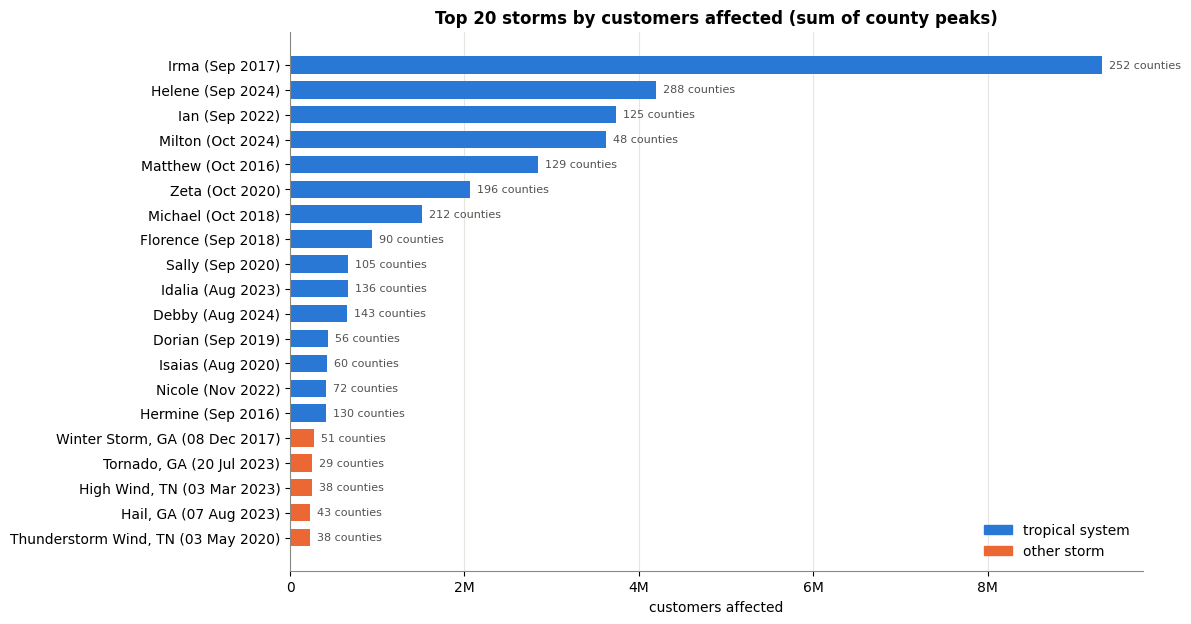

,storm,counties,customers_affected,cust_hours,types
storm_key,,,,,
Irma (Sep 2017),Irma (Sep 2017),252,"9,313,341","188,361,523","Flash Flood, Flood, High Wind, Hurricane (Typhoon), Storm Surge/Tide, Strong Wind, Thunderstorm Wind, Tornado, Tropical Depression, Tropical Storm"
Helene (Sep 2024),Helene (Sep 2024),288,"4,193,048","75,178,910","Debris Flow, Flash Flood, Flood, Funnel Cloud, Heavy Rain, High Wind, Hurricane (Typhoon), Storm Surge/Tide, Strong Wind, Thunderstorm Wind, Tornado, Tropical Depression, Tropical Storm"
Ian (Sep 2022),Ian (Sep 2022),125,"3,735,848","64,058,100","Coastal Flood, Flash Flood, Flood, High Surf, High Wind, Hurricane (Typhoon), Storm Surge/Tide, Strong Wind, Tornado, Tropical Depression, Tropical Storm"
Milton (Oct 2024),Milton (Oct 2024),48,"3,621,472","72,129,234","Flash Flood, Flood, Hurricane (Typhoon), Storm Surge/Tide, Tornado, Tropical Depression, Tropical Storm"
Matthew (Oct 2016),Matthew (Oct 2016),129,"2,847,764","63,176,520","Coastal Flood, Flash Flood, Flood, Heavy Rain, High Surf, High Wind, Hurricane (Typhoon), Storm Surge/Tide, Strong Wind, Tornado, Tropical Depression, Tropical Storm"
Zeta (Oct 2020),Zeta (Oct 2020),196,"2,068,167","21,813,497","Debris Flow, Flash Flood, Flood, Heavy Rain, High Wind, Storm Surge/Tide, Strong Wind, Thunderstorm Wind, Tropical Storm"
Michael (Oct 2018),Michael (Oct 2018),212,"1,511,873","22,463,751","Coastal Flood, Flash Flood, Flood, Funnel Cloud, Heavy Rain, High Surf, High Wind, Hurricane (Typhoon), Storm Surge/Tide, Strong Wind, Thunderstorm Wind, Tornado, Tropical Storm"
Florence (Sep 2018),Florence (Sep 2018),90,"935,537","22,951,548","Coastal Flood, Debris Flow, Flash Flood, Flood, Heavy Rain, High Surf, Hurricane (Typhoon), Strong Wind, Tornado, Tropical Depression, Tropical Storm"
Sally (Sep 2020),Sally (Sep 2020),105,"660,168","12,869,486","Flash Flood, Flood, Heavy Rain, Hurricane (Typhoon), Storm Surge/Tide, Strong Wind, Thunderstorm Wind, Tornado, Tropical Depression, Tropical Storm"


In [ ]:
ep_county = (imp.groupby(["episode_id", "fips_code"])
                .agg(peak=("peak", "max"), cust_hours=("cust_hours", "max"), cust_est=("cust_est", "first")).reset_index()
                .merge(eps[["episode_id", "storm", "event_types"]], on="episode_id"))
# Merge named tropical systems across state episodes; others stay as their own episode
ep_county["storm_key"] = np.where(ep_county["storm"].str.match(r"^[A-Z][a-z]+ \("), ep_county["storm"], ep_county["episode_id"].astype(str))
storms = (ep_county.groupby("storm_key")
            .agg(storm=("storm", "first"), counties=("fips_code", "nunique"), customers_affected=("peak", "sum"),
                 cust_hours=("cust_hours", "sum"),
                 types=("event_types", lambda s: ", ".join(sorted(set(", ".join(s).split(", "))))))
            .sort_values("customers_affected", ascending=False))
named = storms.index.str.match(r"^[A-Z][a-z]+ \(")
storms["kind"] = np.where(named | storms["types"].str.contains("Hurricane|Tropical"), "Tropical", "Other")

top = storms.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(top["storm"], top["customers_affected"], color=[BLUE if k == "Tropical" else ORANGE for k in top["kind"]], height=0.7)
for y, (v, c) in enumerate(zip(top["customers_affected"], top["counties"])):
    ax.text(v, y, f"  {c} counties", va="center", fontsize=8, color="#52514e")
ax.xaxis.set_major_formatter(fmt_k)
ax.grid(axis="y", visible=False)
ax.set(title="Top 20 storms by customers affected (sum of county peaks)", xlabel="customers affected")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=ORANGE)],
          labels=["tropical system", "other storm"], frameon=False, loc="lower right")
plt.show()
storms.head(20)[["storm", "counties", "customers_affected", "cust_hours", "types"]] \
    .style.format({"customers_affected": "{:,.0f}", "cust_hours": "{:,.0f}"})

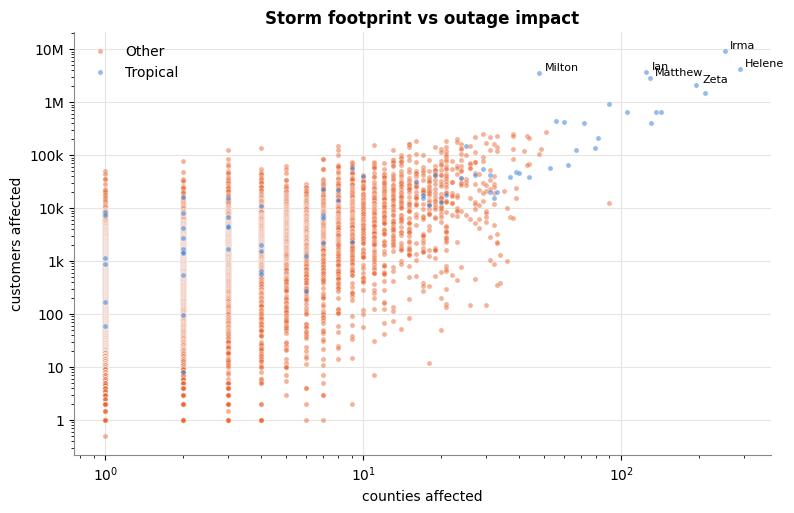

In [ ]:
# Bigger storms (more counties) -> more customers affected? Each dot is one storm.
s = storms[storms["customers_affected"] > 0]
fig, ax = plt.subplots(figsize=(9, 5.5))
for kind, color in [("Other", ORANGE), ("Tropical", BLUE)]:
    k = s[s["kind"] == kind]
    ax.scatter(k["counties"], k["customers_affected"], s=14, color=color, alpha=0.5, edgecolor="white", linewidth=0.4, label=kind)
for _, r in s.head(6).iterrows():
    ax.annotate(r["storm"].split(" (")[0], (r["counties"], r["customers_affected"]), xytext=(4, 2),
                textcoords="offset points", fontsize=8)
ax.set(xscale="log", yscale="log", xlabel="counties affected", ylabel="customers affected",
       title="Storm footprint vs outage impact")
ax.yaxis.set_major_formatter(fmt_k)
ax.legend(frameon=False)
plt.show()

## 7. Does storm strength predict outage size?

These are the candidate model features: wind speed (knots) for wind events, EF rating for tornadoes, hail size, and reported damage.

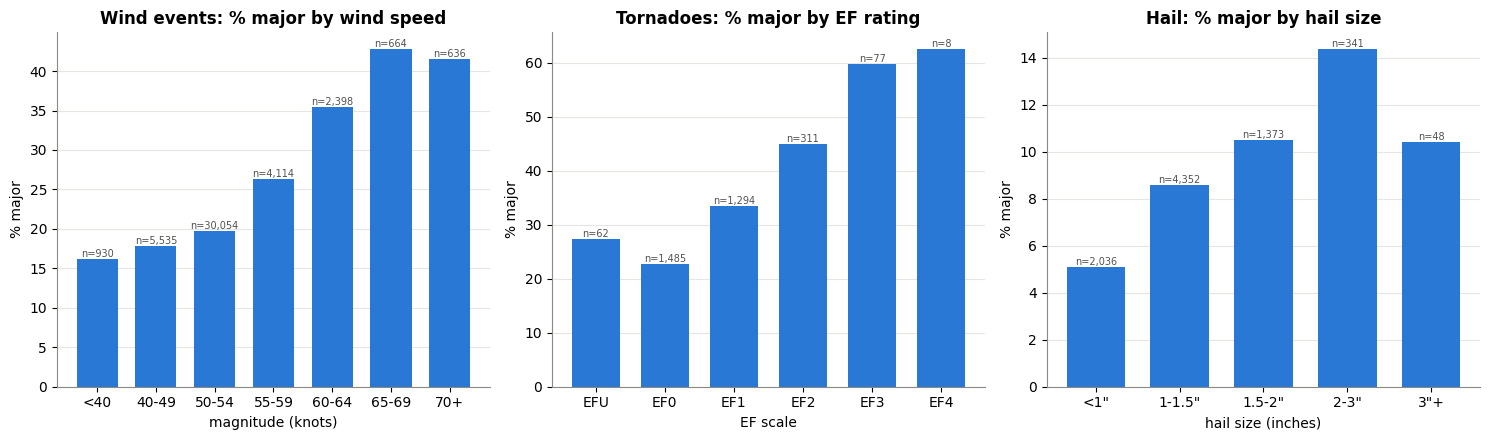

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

w = imp[imp["event_type"].isin(["Thunderstorm Wind", "High Wind", "Strong Wind"]) & imp["magnitude"].notna()].copy()
w["wind_bin"] = pd.cut(w["magnitude"], [0, 40, 50, 55, 60, 65, 70, 200], right=False,
                       labels=["<40", "40-49", "50-54", "55-59", "60-64", "65-69", "70+"])
r = w.groupby("wind_bin", observed=True).agg(pct_major=("major", "mean"), n=("major", "size"))
axes[0].bar(r.index.astype(str), 100 * r["pct_major"], color=BLUE, width=0.7)
for x, (v, n) in enumerate(zip(r["pct_major"], r["n"])):
    axes[0].text(x, 100 * v, f"n={n:,}", ha="center", va="bottom", fontsize=7, color="#52514e")
axes[0].set(title="Wind events: % major by wind speed", xlabel="magnitude (knots)", ylabel="% major")

t = imp[(imp["event_type"] == "Tornado") & imp["tor_f_scale"].notna()]
r = t.groupby("tor_f_scale").agg(pct_major=("major", "mean"), n=("major", "size")).reindex(["EFU", "EF0", "EF1", "EF2", "EF3", "EF4"]).dropna()
axes[1].bar(r.index, 100 * r["pct_major"], color=BLUE, width=0.7)
for x, (v, n) in enumerate(zip(r["pct_major"], r["n"])):
    axes[1].text(x, 100 * v, f"n={int(n):,}", ha="center", va="bottom", fontsize=7, color="#52514e")
axes[1].set(title="Tornadoes: % major by EF rating", xlabel="EF scale", ylabel="% major")

h = imp[(imp["event_type"] == "Hail") & imp["magnitude"].notna()].copy()
h["hail_bin"] = pd.cut(h["magnitude"], [0, 1, 1.5, 2, 3, 10], right=False, labels=['<1"', '1-1.5"', '1.5-2"', '2-3"', '3"+'])
r = h.groupby("hail_bin", observed=True).agg(pct_major=("major", "mean"), n=("major", "size"))
axes[2].bar(r.index.astype(str), 100 * r["pct_major"], color=BLUE, width=0.7)
for x, (v, n) in enumerate(zip(r["pct_major"], r["n"])):
    axes[2].text(x, 100 * v, f"n={n:,}", ha="center", va="bottom", fontsize=7, color="#52514e")
axes[2].set(title="Hail: % major by hail size", xlabel="hail size (inches)", ylabel="% major")
for ax in axes:
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

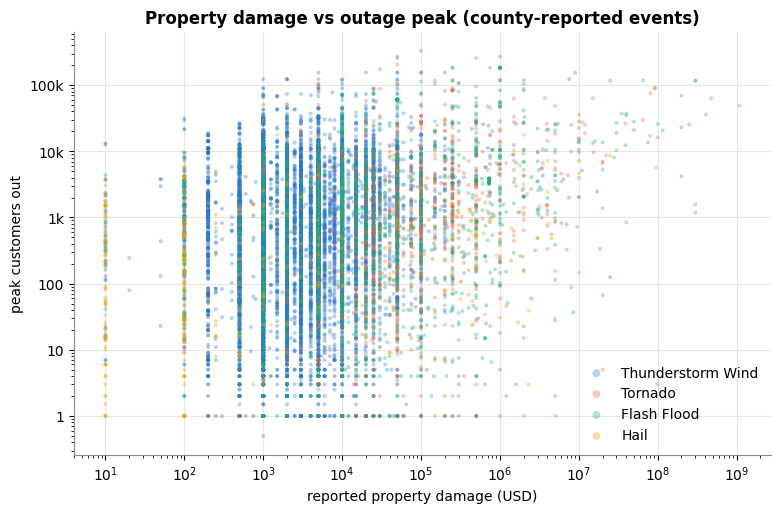

Spearman correlation, damage vs peak share:
                         n  spearman
event_type                          
Tornado             1244.0      0.27
Hail                 367.0      0.27
Flash Flood         2079.0      0.26
Flood                613.0      0.24
Thunderstorm Wind  17153.0      0.10
Lightning            814.0      0.02


In [ ]:
# Reported property damage vs outage peak (event-counties with damage > 0)
d = imp[(imp["damage_property_usd"] > 0) & (imp["peak"] > 0)]
d = d[d["mapped_from"] == "county"]   # zone events repeat one damage number across every county in the zone
fig, ax = plt.subplots(figsize=(9, 5.5))
for ty, color in zip(["Thunderstorm Wind", "Tornado", "Flash Flood", "Hail"], CAT):
    k = d[d["event_type"] == ty]
    ax.scatter(k["damage_property_usd"], k["peak"], s=8, alpha=0.35, color=color, edgecolor="none", label=ty)
ax.set(xscale="log", yscale="log", xlabel="reported property damage (USD)", ylabel="peak customers out",
       title="Property damage vs outage peak (county-reported events)")
ax.yaxis.set_major_formatter(fmt_k)
ax.legend(frameon=False, markerscale=2)
plt.show()

print("Spearman correlation, damage vs peak share:")
print(d.groupby("event_type").apply(lambda g: pd.Series({"n": len(g), "spearman": g["damage_property_usd"].corr(g["peak_share"], method="spearman")}))
       .query("n >= 100").sort_values("spearman", ascending=False).round(2))

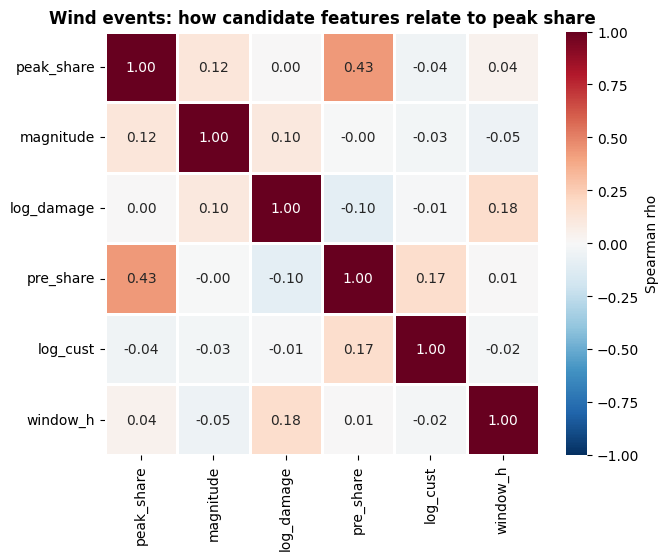

In [ ]:
# Numeric features vs peak share in one view (Spearman, wind events only)
w["log_damage"] = np.log1p(w["damage_property_usd"])
w["pre_share"] = w["pre_level"] / w["cust_est"]
w["log_cust"] = np.log(w["cust_est"])
w["window_h"] = (w["w1"] - w["w0"]).dt.total_seconds() / 3600
corr = w[["peak_share", "magnitude", "log_damage", "pre_share", "log_cust", "window_h"]].corr(method="spearman")

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", linewidths=1, linecolor="white", ax=ax,
            cbar_kws={"label": "Spearman rho"})
ax.set_title("Wind events: how candidate features relate to peak share")
heat_axes(ax, months=False)
plt.show()

## 8. How many big outages have a storm on record?

Now start from the outages. Take every **major outage onset**, meaning the first day of a run of days where a county's peak is
5% or more of estimated customers *and* at least 1,000 customers. Requiring 1,000 keeps tiny counties out, and using only the first
day stops multi-day restoration from being counted again. Then check for a NOAA storm event within one day either side:
- **in the county**: the storm-county table has an event for this county
- **elsewhere in the state only**: NOAA logged something in the state that day, but it didn't map to this county
  (often a forecast zone that failed to map, see notebook 02)
- **none in the state**: no NOAA event in the whole state. These are equipment failures, heat load, or weather NOAA didn't log.

In [ ]:
STORM_EVENTS = (C.PROCESSED_DIR / "storms" / "storm_events_*.parquet").as_posix()
cd = con.sql(f'''
with days as (
  select h.fips_code, cast(h.hr as date) as day, max(h.out) as peak, max(h.out / c.cust_est) as pshare
  from hourly h join cust c on c.fips_code = h.fips_code and c.acs_year = least(year(h.hr), 2024)
  group by all
),
flag as (
  select *, pshare >= {MAJOR} and peak >= 1000 as is_major,
         lag(pshare >= {MAJOR} and peak >= 1000) over w as prev_major, lag(day) over w as prev_day
  from days window w as (partition by fips_code order by day)
),
onset as (select * from flag where is_major and not (coalesce(prev_major, false) and prev_day = day - 1)),
county_days as (   -- skip month-long drought/heat rows
  select distinct fips_code, unnest(generate_series(cast(begin_utc as date) - 1, cast(end_utc as date) + 1, interval 1 day))::date as day
  from '{STORMS}' where end_utc - begin_utc < interval 10 day
),
state_days as (    -- raw NOAA events, including zone events that never mapped to a county
  select distinct state_fips, unnest(generate_series(cast(begin_utc as date) - 1, cast(end_utc as date) + 1, interval 1 day))::date as day
  from '{STORM_EVENTS}' where end_utc - begin_utc < interval 10 day
)
select o.fips_code, o.day, o.peak, o.pshare,
       case when cd.fips_code is not null then 'in the county'
            when sd.state_fips is not null then 'elsewhere in the state only'
            else 'none in the state' end as storm_record
from onset o
left join county_days cd on cd.fips_code = o.fips_code and cd.day = o.day
left join state_days sd on sd.state_fips = left(o.fips_code, 2) and sd.day = o.day
''').df()
cd["year"] = pd.to_datetime(cd["day"]).dt.year
cd["state"] = cd["fips_code"].str[:2].map(C.STATES)
REC = ["in the county", "elsewhere in the state only", "none in the state"]

print(f"{len(cd):,} major-outage onsets")
pd.concat({"share of onsets": cd["storm_record"].value_counts(normalize=True),
           "share of peak customers": cd.groupby("storm_record")["peak"].sum() / cd["peak"].sum()}, axis=1) \
    .loc[REC].style.format("{:.0%}")

15,521 major-outage onsets


,share of onsets,share of peak customers
storm_record,,
in the county,36%,61%
elsewhere in the state only,47%,29%
none in the state,17%,10%


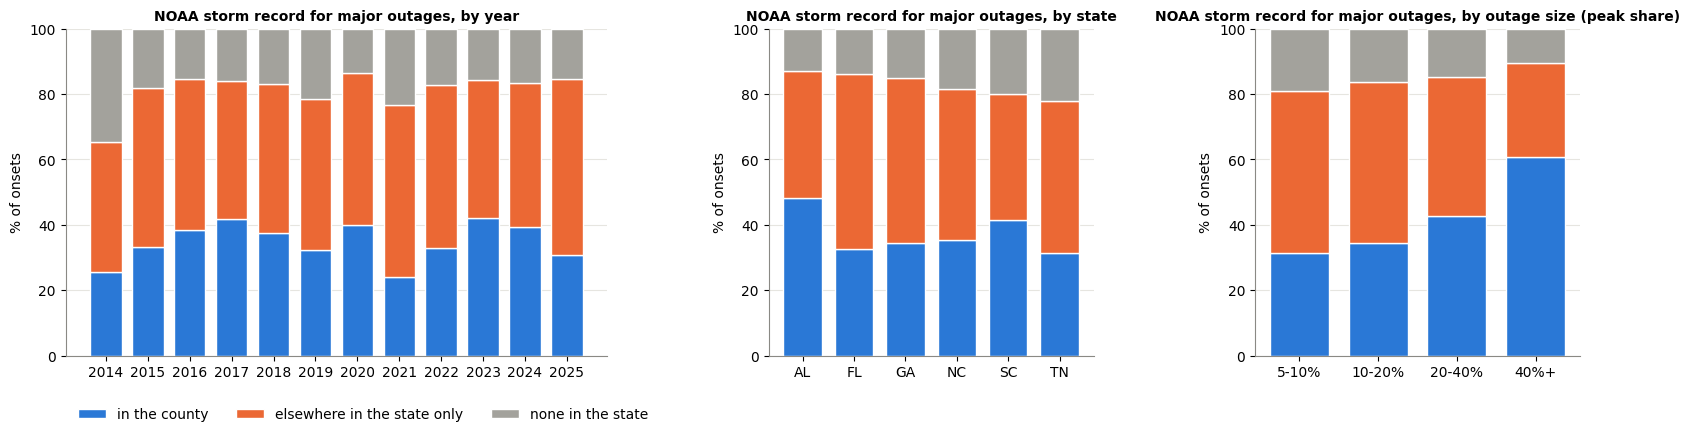

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), gridspec_kw={"width_ratios": [2, 1.2, 1.2]})
cd["size_bin"] = pd.cut(cd["pshare"], [0.05, 0.10, 0.20, 0.40, 1.01], right=False, labels=["5-10%", "10-20%", "20-40%", "40%+"])
for ax, col, title in zip(axes, ["year", "state", "size_bin"], ["by year", "by state", "by outage size (peak share)"]):
    r = pd.crosstab(cd[col], cd["storm_record"], normalize="index")[REC] * 100
    bottom = np.zeros(len(r))
    for rec, color in zip(REC, [BLUE, ORANGE, GREY]):
        ax.bar(r.index.astype(str), r[rec], bottom=bottom, color=color, width=0.75, edgecolor="white", linewidth=1, label=rec)
        bottom += r[rec].values
    ax.set(title=f"NOAA storm record for major outages, {title}", ylabel="% of onsets", ylim=(0, 100))
    ax.title.set_fontsize(10)
    ax.grid(axis="x", visible=False)
axes[0].legend(frameon=False, ncol=3, loc="upper left", bbox_to_anchor=(0, -0.12))
plt.tight_layout()
plt.show()

In [ ]:
# The biggest outages with no storm in the county: mostly mapping gaps, not storm-free outages
miss = cd[cd["storm_record"] != "in the county"].nlargest(15, "peak")
miss = miss.merge(county[["fips_code", "label"]], on="fips_code", how="left")
miss[["label", "day", "peak", "pshare", "storm_record"]].style.format({"peak": "{:,.0f}", "pshare": "{:.0%}"})

,label,day,peak,pshare,storm_record
0,"Charleston, SC",2019-09-05 00:00:00,"135,815",60%,elsewhere in the state only
1,"Chatham, GA",2024-09-27 00:00:00,"118,652",72%,elsewhere in the state only
2,"Pinellas, FL",2024-09-26 00:00:00,"88,670",14%,elsewhere in the state only
3,"Miami-Dade, FL",2025-05-20 00:00:00,"76,064",6%,elsewhere in the state only
4,"St. Johns, FL",2016-10-07 00:00:00,"74,974",64%,elsewhere in the state only
5,"Escambia, FL",2024-08-21 00:00:00,"71,216",40%,elsewhere in the state only
6,"Greenville, SC",2020-10-29 00:00:00,"71,008",28%,elsewhere in the state only
7,"DeKalb, GA",2023-06-25 00:00:00,"65,906",17%,elsewhere in the state only
8,"Greenville, SC",2018-12-09 00:00:00,"59,202",24%,elsewhere in the state only
9,"Hamilton, TN",2025-06-13 00:00:00,"57,278",28%,elsewhere in the state only


## 9. Summary

**Data checks**
- **EAGLE-I timestamps are UTC** (section 1). Join on NOAA `begin_utc` / `end_utc`; no time-zone shift is needed.
- One bad 15-min reading can double a county's total for one hour (Irma reaches 10M for one hour, then drops back to 7.5M). Use the
  hourly **median**, not the max, and cap at estimated customers.

**Which storm types cause the most outages**
- **Per event:** Hurricane (99% of event-counties have a major outage; median peak 75% of customers) > Tropical Storm (58%) >
  Storm Surge (54%) > Ice Storm (36%) > High Wind (31%) ≈ Tornado (30%) > Strong Wind (25%) > Thunderstorm Wind (21%).
  Hail (8%), Lightning (4%), Heavy Rain (7%) and Winter Weather (3%) rarely cause major outages.
- **In total:** Thunderstorm Wind is tied with Tropical Storm for the most customer-hours out (~540M each). Its per-event rate is
  low, but there are 42k of them. Our model has to handle routine convective storms, not just hurricanes.
- **Seasonality:** most major outages from thunderstorm wind happen Apr-Aug (peak June). Per event, though, winter thunderstorms
  (Jan-Feb, median 2.2% out) are worse than summer ones (Jul-Sep, 0.6-1.1%), probably because winter squall lines are larger.
  Tropical outages fall in Aug-Oct, and winter storms in Dec-Feb.
- **Timing:** convective outages peak a median of **2 h** after the storm starts (90% within 5-9 h). Hurricanes peak at **14 h**
  (90th percentile 28 h), and winter and ice storms at about **13 h**. The target window needs to reach at least a day past the start
  for those types.

**When and where most customers were out**
- The six biggest region-wide peaks are all hurricanes: **Irma** (8.0M out, 11 Sep 2017), **Helene** (4.3M, 27 Sep 2024),
  **Milton** (3.4M, 10 Oct 2024), **Ian** (2.5M, 29 Sep 2022), **Matthew** (1.9M, Oct 2016), **Zeta** (1.9M, Oct 2020).
  The biggest non-tropical peak is the **Dec 2022 Arctic outbreak** (970k on 24 Dec, cold/wind chill in NC; this was Winter Storm
  Elliott, when Duke and TVA ran rolling blackouts). The storm data only explains 17% of that peak, so NOAA events miss grid-stress outages.
- The worst months by customer-hours are Sep 2017 (Irma), Oct 2024 (Milton), Sep 2024 (Helene), Oct 2016 (Matthew) and Sep/Oct 2022 (Ian).
- **Florida** dominates the totals (tropical systems hit its large coastal metros). Of the top 20 counties by storm customer-hours,
  all but Shelby TN, Davidson TN, Mecklenburg NC and Wake NC are in Florida.
  Per event, though, **Georgia, NC and SC** have the highest rate of major outages from tropical storms (62-71%), mostly from inland
  wind damage on overhead lines. Small rural counties (Coosa AL, Pike GA, Taylor GA) have a major outage in 63-73% of storms.

**Storm strength**
- Strength features do predict outages: wind events go from 16% major below 40 kt to 42% at 65+ kt, tornadoes from 23% (EF0) to
  60% (EF3), and hail from 5% (<1") to 14% (2-3").
- Reported property damage is a weak predictor (Spearman 0.10 for thunderstorm wind, about 0.25 for tornado, hail and flood). It is
  also only known after the storm, so **don't use it as a feature** (leakage).
- The outage level in the 24 h before an event correlates with its peak (rho 0.43), because storms come in clusters. A
  "pre-storm outage level" or "storms in the past day" feature should help.

**Storm data coverage**
- Of 15,521 major-outage onsets, **36% have a NOAA event in that county**, but these hold **61% of the peak customers**. The bigger
  the outage, the more likely it has a storm record (about 60% of outages above 40% of customers).
- 47% have a NOAA event only elsewhere in the state. Several of the largest are **zone-mapping gaps** from notebook 02: Charleston
  SC during Dorian (136k out) and Chatham GA during Helene (119k out) have no county event at all. **Fixing the old zone codes
  (Charleston, Coastal Chatham, Beaufort, ...) should be a priority** before modeling.
- 17% have no NOAA event in the whole state (equipment, heat load, or weather NOAA didn't log). A storm-driven model can't predict these.

**Next steps for modeling**
1. Build one row per (storm episode or named storm, county), with the outage target over a window that reaches 24-36 h past the start.
2. Features: event type mix, max wind / EF / hail size, month, tropical flag, county customers and density, pre-storm outage level.
3. Fix zone mapping for the coastal SC/GA zones and the 59 GA winter-storm rows with bad FIPS codes.
4. Treat 2017 (Irma) peaks with care: EAGLE-I double counting is common in that year.